<a href="https://colab.research.google.com/github/awmsxf1/awmsxf1/blob/main/%EC%8B%A4%EC%8A%B502.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np
import matplotlib.pyplot as plt

LEN = 500           # 기본 정사각형(p1~p4)의 한 변의 길이
COLOR = 'tab:blue'  # TIE Fighter 색


# 좌표축 그리기 (-1000 ~ 1000)
def draw_axis(ax):
  ax.set_xlim(-1000, 1000)
  ax.set_ylim(-1000, 1000)
  ax.set_xticks(range(-1000, 1001, 250))
  ax.set_yticks(range(-1000, 1001, 250))
  ax.axhline(0, color='gray', alpha=0.5)
  ax.axvline(0, color='gray', alpha=0.5)
  ax.set_aspect('equal')

In [15]:
# (기존) 이동 / 크기 / 회전 : 작성하신 코드 그대로입니다.
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q


def scale(p, sx, sy):
    m = np.array([
        [sx, 0.0, 0.0],
        [0.0, sy, 0.0],
        [0.0, 0.0, 1.0]
    ])

    hp = np.array([p[0], p[1], 1.0])
    q = np.dot(m, hp)

    return np.array([q[0], q[1]])


def rotate(p, theta):
    m = np.array([
        [np.cos(theta), -np.sin(theta), 0.0],
        [np.sin(theta),  np.cos(theta), 0.0],
        [0.0, 0.0, 1.0]
    ])

    hp = np.array([p[0], p[1], 1.0])
    q = np.dot(m, hp)

    return np.array([q[0], q[1]])

In [16]:
# (추가) 3x3 변환 행렬 m 을 점 p 에 적용하는 공통 함수
def apply_matrix(m, p):
  hp = np.array([p[0], p[1], 1.0])  # 1. 동차좌표계로 변환
  q = np.dot(m, hp)                 # 2. 행렬과 벡터의 곱 (3,3) x (3,1) -> (3,1)
  return np.array([q[0], q[1]])     # 3. 2차원 좌표계로 변환


# ---- 기울기 (shear) ----
# x축 방향 기울이기 : x' = x + k*y
def shear_x(p, k):
  m = np.array([
    [1.0, k,   0.0],
    [0.0, 1.0, 0.0],
    [0.0, 0.0, 1.0]
  ])
  return apply_matrix(m, p)


# y축 방향 기울이기 : y' = y + k*x
def shear_y(p, k):
  m = np.array([
    [1.0, 0.0, 0.0],
    [k,   1.0, 0.0],
    [0.0, 0.0, 1.0]
  ])
  return apply_matrix(m, p)


# ---- 반전 (reflection) ----
# x축 기준 반전 : (x, y) -> (x, -y)
def reflect_x(p):
  m = np.array([
    [1.0,  0.0, 0.0],
    [0.0, -1.0, 0.0],
    [0.0,  0.0, 1.0]
  ])
  return apply_matrix(m, p)


# y축 기준 반전 : (x, y) -> (-x, y)
def reflect_y(p):
  m = np.array([
    [-1.0, 0.0, 0.0],
    [ 0.0, 1.0, 0.0],
    [ 0.0, 0.0, 1.0]
  ])
  return apply_matrix(m, p)


# 원점 기준 반전 : (x, y) -> (-x, -y)
def reflect_origin(p):
  m = np.array([
    [-1.0,  0.0, 0.0],
    [ 0.0, -1.0, 0.0],
    [ 0.0,  0.0, 1.0]
  ])
  return apply_matrix(m, p)


# 직선 y=x 기준 반전 : (x, y) -> (y, x)
def reflect_yx(p):
  m = np.array([
    [0.0, 1.0, 0.0],
    [1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0]
  ])
  return apply_matrix(m, p)

In [17]:
# ---- 부품 크기 (예시 그림에 맞춘 값) ----
ARM_LEN   = 800     # 팔의 길이
ARM_THICK = 80      # 팔을 이루는 평행사변형 하나의 두께
ARM_BASE  = 60      # 평행사변형 아랫변의 시작 높이 (y)
ARM_SHEAR = -0.125  # 바깥쪽으로 갈수록 가늘어지도록 기울이는 정도

WING_X     = 750    # 날개 안쪽 변의 x 좌표
WING_W     = 100    # 날개의 가로 두께
WING_H     = 800    # 날개 안쪽 변의 세로 길이
WING_SHEAR = 2.0    # 바깥쪽 변이 위/아래로 200씩 더 길어지도록 기울이는 정도


# 점 목록 전체에 변환 함수를 한 번에 적용
def transform_points(points, func, *args):
  return [func(p, *args) for p in points]


# 점 목록을 이어서 색칠한 다각형으로 그리기
def draw_polygon(ax, points):
  xs = [p[0] for p in points]
  ys = [p[1] for p in points]
  ax.fill(xs, ys, color=COLOR)

In [18]:
# 중앙 조종석 : 정사각형을 45도 돌려 마름모로 만든 뒤, 중심이 원점에 오도록 이동
def draw_cockpit(ax, p1, p2, p3, p4):
  q = transform_points([p1, p2, p3, p4], rotate, np.pi / 4)  # 회전
  q = transform_points(q, translate, 0, -LEN / np.sqrt(2))    # 이동
  draw_polygon(ax, q)

In [19]:
# 오른쪽 팔을 이루는 평행사변형 2개 (위쪽, 아래쪽)
# ※ 두 평행사변형 사이에 생기는 빈틈이 조종석 옆에서 작은 흰 화살촉으로 보이는데,
#   예시 그림에도 있는 모양입니다. (없애려면 ARM_BASE 를 줄이고 그만큼 ARM_THICK 를 늘리세요. 예: 30 / 110)
def make_right_arm(p1, p2, p3, p4):
  q = transform_points([p1, p2, p3, p4], scale, ARM_LEN / LEN, ARM_THICK / LEN)  # 800 x 80 직사각형
  q = transform_points(q, translate, 0, ARM_BASE)                                # 위로 이동 (y: 60~140)
  upper = transform_points(q, shear_y, ARM_SHEAR)                                # 기울여서 평행사변형
  lower = transform_points(upper, reflect_x)                                     # x축 반전 -> 아래쪽
  return [upper, lower]


# 오른쪽 팔 그리기
def draw_right_arm(ax, p1, p2, p3, p4):
  for poly in make_right_arm(p1, p2, p3, p4):
    draw_polygon(ax, poly)


# 왼쪽 팔 : 오른쪽 팔을 y축 기준으로 반전
def draw_left_arm(ax, p1, p2, p3, p4):
  for poly in make_right_arm(p1, p2, p3, p4):
    draw_polygon(ax, transform_points(poly, reflect_y))

In [20]:
# 오른쪽 날개를 이루는 평행사변형 2개 (위쪽, 아래쪽)
def make_right_wing(p1, p2, p3, p4):
  q = transform_points([p1, p2, p3, p4], scale, WING_W / LEN, WING_H / LEN)  # 100 x 800 직사각형
  q = transform_points(q, translate, 0, -WING_H / 2)                         # 위아래 가운데 정렬 (y: -400~400)
  q = transform_points(q, shear_y, WING_SHEAR)                               # 기울여서 평행사변형
  upper = transform_points(q, translate, WING_X, 0)                          # 오른쪽으로 이동 (x: 750~850)
  lower = transform_points(upper, reflect_x)                                 # x축 반전 -> 아래쪽
  return [upper, lower]


# 오른쪽 날개 그리기
def draw_right_wing(ax, p1, p2, p3, p4):
  for poly in make_right_wing(p1, p2, p3, p4):
    draw_polygon(ax, poly)


# 왼쪽 날개 : 오른쪽 날개를 원점 기준으로 반전
def draw_left_wing(ax, p1, p2, p3, p4):
  for poly in make_right_wing(p1, p2, p3, p4):
    draw_polygon(ax, transform_points(poly, reflect_origin))

In [21]:
# 2. tiefighter 그리기
def draw_object(ax):
  # 모든 부품의 출발점이 되는 정사각형
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 팔 그리기
  draw_right_arm(ax, p1, p2, p3, p4)
  draw_left_arm(ax, p1, p2, p3, p4)

  # 3. 날개 그리기
  draw_right_wing(ax, p1, p2, p3, p4)
  draw_left_wing(ax, p1, p2, p3, p4)

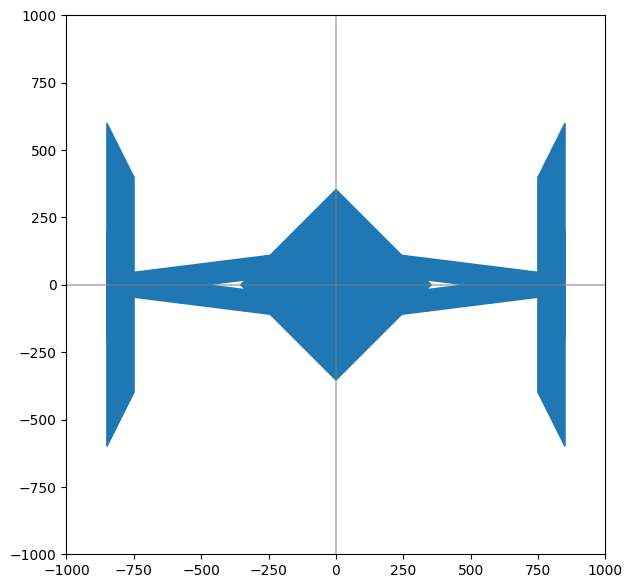

In [22]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()